# Homework 2

Problem 1: Predicting a mean *and* a standard deviation 

> So far in this course we have focused on fitting models $f_\mu(x)$ to approximate $E[Y\mid X]$, the conditional mean of
> the target $Y$ given the input $X$. Suppose we want to also incorporate a measure of uncertainty in our observations of
> $Y$, in the form of a function $f_\sigma(x) = \sqrt{\mathrm{Var}(Y\mid X=x)}$ (the conditional standard deviation) which
> models how the observation noise changes with the input $X$.


## Setup

In [55]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset


## (a) A link function for $(f_\mu, f_\sigma)$

> Say we have a neural architecture $g:\mathbb R^p \to \mathbb R^2$ that takes in a $p$-dimensional feature vector and
> returns a 2-dimensional vector of real numbers. Suggest a link function that would be appropriate for converting the
> output to $f_\mu$ and $f_\sigma$.

Let $g(x) = (g_1(x), g_2(x))$. The mean can be any real number, but a standard deviation must be positive, so

$$f_\mu(x) = g_1(x) \quad\text{(identity)}, \qquad f_\sigma(x) = \operatorname{softplus}(g_2(x)) + \varepsilon = \log\!\big(1 + e^{g_2(x)}\big) + \varepsilon .$$


## (b) A loss function from $Y\mid X \sim \mathcal N(f_\mu(X), f_\sigma(X)^2)$

> We could model data of this form as $Y\mid X \sim \mathcal N(f_\mu(X), f_\sigma(X)^2)$. Write down a loss function we
> could use for model training based on this model.

By using the negative log-likelihood. The loss would be
$$-\log p(y_i\mid x_i) = \log f_\sigma(x_i) + \frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2} + \tfrac12 \log(2\pi),$$
so the average training loss is
$$\boxed{\;L(\theta) = \frac1n\sum_{i=1}^n\Big[\log f_\sigma(x_i) + \frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2}\Big]\;}$$



## (c) Fit a mean-and-standard-deviation MLP on the taxi data

> Define a multi-layer perceptron in PyTorch or JAX that outputs a conditional mean and standard deviation, and fit
> this on the taxi trip dataset. Make sure to follow best practices: define a baseline (or multiple) baseline models that
> you think your model should beat, split your dataset into training/validation/test sets, etc.

### Load data

In [56]:
df = pd.read_parquet("taxi_trips.parquet").reset_index(drop=True)
df = df.drop(columns=[c for c in df.columns if c.startswith("__index")], errors="ignore")
TARGET = "trip_duration"
FEATURES = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
            "min_of_day", "day_of_week", "day_of_year"]
X_all = df[FEATURES].to_numpy(np.float32)
y_all = df[TARGET].to_numpy(np.float32)
print(df.shape)
df.describe().T.round(3)

(523554, 8)


,count,mean,std,min,25%,50%,75%,max
pickup_longitude,523554.0,-0.000,1.000,-33.361,-0.537,-0.154,0.370,29.372
pickup_latitude,523554.0,-0.000,1.000,-14.299,-0.573,0.071,0.631,13.277
dropoff_longitude,523554.0,0.000,1.000,-33.478,-0.575,-0.147,0.429,52.664
dropoff_latitude,523554.0,0.000,1.000,-12.746,-0.554,0.059,0.610,20.876
trip_duration,523554.0,10.413,7.754,0.033,4.750,8.631,13.928,227.943
min_of_day,523554.0,0.000,1.000,-2.210,-0.717,0.100,0.839,1.559
day_of_week,523554.0,0.000,1.000,-1.557,-1.048,-0.028,0.991,1.501
day_of_year,523554.0,0.000,1.000,-1.745,-0.854,-0.001,0.851,1.762


trip duration (minutes): mean 10.41, sd 7.75, median 8.63, max 227.9
share of trips under 45 minutes: 99.5601%


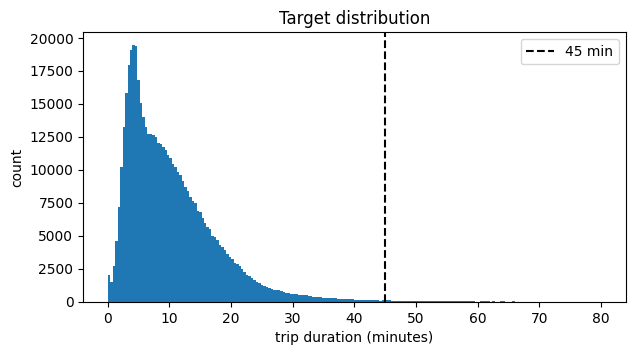

In [57]:
print(f"trip duration (minutes): mean {y_all.mean():.2f}, sd {y_all.std():.2f}, median {np.median(y_all):.2f}, max {y_all.max():.1f}")
print(f"share of trips under 45 minutes: {(y_all < 45).mean():.4%}")
plt.figure(figsize=(7, 3.5))
plt.hist(y_all, bins=200, range=(0, 80))
plt.axvline(45, color="k", ls="--", label="45 min")
plt.xlabel("trip duration (minutes)"); plt.ylabel("count"); plt.legend(); plt.title("Target distribution")
plt.show()

The features are already standardised (mean 0, sd 1). The target is right-skewed: most trips take 5–15 minutes, with a
long tail. Over 99.5 % of trips take less than 45 minutes, which matters a lot for part (e).

### Train/Validation/Test split


In [58]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(y_all))
n_tr, n_va = int(0.70 * len(perm)), int(0.15 * len(perm))
idx_tr, idx_va, idx_te = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]
X_tr, y_tr = X_all[idx_tr], y_all[idx_tr]
X_va, y_va = X_all[idx_va], y_all[idx_va]
X_te, y_te = X_all[idx_te], y_all[idx_te]
print("train", len(y_tr), "| val", len(y_va), "| test", len(y_te))

train 366487 | val 78533 | test 78534


### Baselines
Every model below outputs a full predictive distribution $\mathcal N(\mu(x), \sigma(x)^2)$, so all of them can be scored
with the same Gaussian NLL and later with the same probability metrics.

* B0, constant Gaussian.
* B1, linear mean + constant SD.
* B2, MLP mean + constant SD.

In [59]:
def nll_np(y, mu, sigma):
    return float(np.mean(np.log(sigma) + 0.5 * ((y - mu) / sigma) ** 2 + 0.5 * np.log(2 * np.pi)))

def rmse_np(y, mu):
    return float(np.sqrt(np.mean((y - mu) ** 2)))

predictions = {}   # name -> function X -> (mu, sigma) in minutes

# B0: constant Gaussian
mu0, sd0 = float(y_tr.mean()), float(y_tr.std())
predictions["B0 constant Gaussian"] = lambda X: (np.full(len(X), mu0), np.full(len(X), sd0))

# B1: linear regression mean, constant SD of residuals
A_tr = np.c_[np.ones(len(X_tr)), X_tr]
coef_lin = np.linalg.lstsq(A_tr, y_tr, rcond=None)[0]
sd1 = float(np.std(y_tr - A_tr @ coef_lin))
predictions["B1 linear mean + const SD"] = lambda X: (np.c_[np.ones(len(X)), X] @ coef_lin, np.full(len(X), sd1))

for name, f in predictions.items():
    mu, s = f(X_va)
    print(f"{name:28s} val NLL {nll_np(y_va, mu, s):.4f} | val RMSE {rmse_np(y_va, mu):.3f}")

B0 constant Gaussian         val NLL 3.4655 | val RMSE 7.741
B1 linear mean + const SD    val NLL 3.4380 | val RMSE 7.531


### The model
An MLP body (7 → 128 → 128, ReLU) followed by a linear head with **2 outputs** $g(x) = (g_1, g_2)$ and the link function from (a).

In [60]:
class MeanStdMLP(nn.Module):
    def __init__(self, d_in, hidden=(128, 128), n_out=2):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, n_out)
        self.n_out = n_out

    def forward(self, x):
        g = self.head(self.body(x))
        mu = g[:, 0]                                   # identity link for the mean
        if self.n_out == 1:
            return mu
        sigma = F.softplus(g[:, 1]) + 1e-3             # softplus link: sigma > 0
        return mu, sigma


y_mean, y_sd = float(y_tr.mean()), float(y_tr.std())

def to_loader(X, y, batch_size, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy((y - y_mean) / y_sd))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

@torch.no_grad()
def predict_std_units(model, X, batch_size=65536):
    model.eval()
    outs = [model(torch.from_numpy(X[i:i + batch_size]).to(device)) for i in range(0, len(X), batch_size)]
    if isinstance(outs[0], tuple):
        return (torch.cat([o[0] for o in outs]).cpu().numpy(), torch.cat([o[1] for o in outs]).cpu().numpy())
    return torch.cat(outs).cpu().numpy()

def fit(model, loss_fn, val_metric, max_epochs=30, patience=3, lr=1e-3, batch_size=1024):
    # Adam + early stopping on a validation metric; returns the model with the best validation weights.
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    train_loader = to_loader(X_tr, y_tr, batch_size, shuffle=True)
    best, best_state, bad, history = float("inf"), None, 0, []
    for epoch in range(max_epochs):
        model.train()
        total = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        v = val_metric(model)
        history.append((epoch, total / len(X_tr), v))
        print(f"epoch {epoch:2d} | train loss {total / len(X_tr):.4f} | val metric {v:.4f}")
        if v < best - 1e-4:
            best, bad = v, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"early stopping after epoch {epoch} (best val metric {best:.4f})")
                break
    model.load_state_dict(best_state)
    return model, history

**Baseline B2 (homoscedastic MLP):** same body, one output, MSE loss; early stopping on validation MSE.

In [61]:
torch.manual_seed(SEED)
mlp_mean = MeanStdMLP(len(FEATURES), n_out=1)
mlp_mean, hist_b2 = fit(
    mlp_mean,
    loss_fn=lambda mu, yb: F.mse_loss(mu, yb),
    val_metric=lambda m: float(np.mean((predict_std_units(m, X_va) * y_sd + y_mean - y_va) ** 2)),
)
sd2 = float(np.std(y_tr - (predict_std_units(mlp_mean, X_tr) * y_sd + y_mean)))
predictions["B2 MLP mean + const SD"] = lambda X: (predict_std_units(mlp_mean, X) * y_sd + y_mean, np.full(len(X), sd2))

epoch  0 | train loss 0.4071 | val metric 18.8675
epoch  1 | train loss 0.2975 | val metric 17.1948
epoch  2 | train loss 0.2801 | val metric 16.6529
epoch  3 | train loss 0.2712 | val metric 16.1473
epoch  4 | train loss 0.2652 | val metric 15.7617
epoch  5 | train loss 0.2602 | val metric 15.7672
epoch  6 | train loss 0.2573 | val metric 15.5477
epoch  7 | train loss 0.2547 | val metric 15.5314
epoch  8 | train loss 0.2523 | val metric 15.2871
epoch  9 | train loss 0.2515 | val metric 15.0853
epoch 10 | train loss 0.2490 | val metric 15.1860
epoch 11 | train loss 0.2474 | val metric 15.1266
epoch 12 | train loss 0.2464 | val metric 15.1757
early stopping after epoch 12 (best val metric 15.0853)


**Our model:** same body, two outputs, Gaussian NLL loss from (b); early stopping on validation NLL.

In [62]:
def gaussian_nll(y, mu, sigma):
    # average negative log-likelihood of y under N(mu, sigma^2), including the constant 0.5*log(2*pi)
    return (torch.log(sigma) + 0.5 * ((y - mu) / sigma) ** 2).mean() + 0.5 * math.log(2 * math.pi)

In [63]:
torch.manual_seed(SEED)
model = MeanStdMLP(len(FEATURES), n_out=2)

def val_nll(m):
    mu_s, sig_s = predict_std_units(m, X_va)
    return nll_np(y_va, mu_s * y_sd + y_mean, sig_s * y_sd)

model, hist = fit(model, loss_fn=lambda out, yb: gaussian_nll(yb, out[0], out[1]), val_metric=val_nll)

def predict_mu_sigma(X):
    mu_s, sig_s = predict_std_units(model, X)
    return mu_s * y_sd + y_mean, sig_s * y_sd

predictions["Mean+SD MLP (ours)"] = predict_mu_sigma

epoch  0 | train loss 0.8672 | val metric 2.7854
epoch  1 | train loss 0.7100 | val metric 2.7432
epoch  2 | train loss 0.6772 | val metric 2.7669
epoch  3 | train loss 0.6529 | val metric 2.7439
epoch  4 | train loss 0.6422 | val metric 2.6926
epoch  5 | train loss 0.6329 | val metric 2.6862
epoch  6 | train loss 0.6271 | val metric 2.6924
epoch  7 | train loss 0.6154 | val metric 2.6909
epoch  8 | train loss 0.6136 | val metric 2.6764
epoch  9 | train loss 0.6035 | val metric 2.6715
epoch 10 | train loss 0.6023 | val metric 2.6694
epoch 11 | train loss 0.5967 | val metric 2.6621
epoch 12 | train loss 0.5897 | val metric 2.6930
epoch 13 | train loss 0.5877 | val metric 2.6674
epoch 14 | train loss 0.5855 | val metric 2.6638
early stopping after epoch 14 (best val metric 2.6621)


In [64]:
rows = []
for name, f in predictions.items():
    mu, s = f(X_va)
    rows.append({"model": name, "val NLL": nll_np(y_va, mu, s), "val RMSE (min)": rmse_np(y_va, mu)})
pd.DataFrame(rows).set_index("model").round(4)

,val NLL,val RMSE (min)
model,,
B0 constant Gaussian,3.4655,7.7410
B1 linear mean + const SD,3.4380,7.5310
B2 MLP mean + const SD,2.7759,3.8840
Mean+SD MLP (ours),2.6621,3.9976


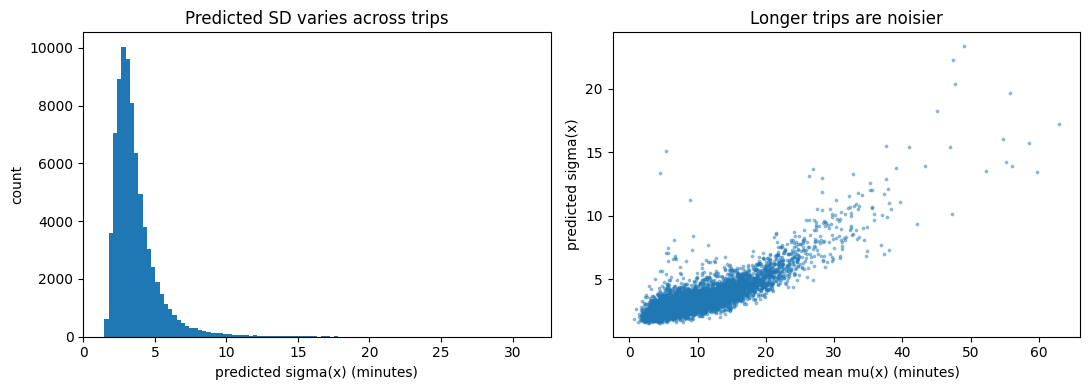

standardised residuals on validation: mean -0.065, sd 1.021 (a calibrated model gives about 0 and 1)


In [65]:
mu_va, sig_va = predict_mu_sigma(X_va)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(sig_va, bins=100)
axes[0].set(xlabel="predicted sigma(x) (minutes)", ylabel="count", title="Predicted SD varies across trips")
sub = np.random.default_rng(1).choice(len(mu_va), 5000, replace=False)
axes[1].scatter(mu_va[sub], sig_va[sub], s=3, alpha=0.4)
axes[1].set(xlabel="predicted mean mu(x) (minutes)", ylabel="predicted sigma(x)", title="Longer trips are noisier")
plt.tight_layout(); plt.show()

z = (y_va - mu_va) / sig_va
print(f"standardised residuals on validation: mean {z.mean():.3f}, sd {z.std():.3f} (a calibrated model gives about 0 and 1)")

## (d) Probability that a trip takes less than 45 minutes

> How would we use the model we've just fit to predict the probability that a trip will take less than 45 minutes? The
> normal distribution assumption is fine.

Under the model, $T \mid X = x \sim \mathcal N(f_\mu(x), f_\sigma(x)^2)$. Standardising,

$$P(T < 45 \mid X = x) = P\Big(\frac{T - f_\mu(x)}{f_\sigma(x)} < \frac{45 - f_\mu(x)}{f_\sigma(x)}\Big) = \Phi\Big(\frac{45 - f_\mu(x)}{f_\sigma(x)}\Big),$$


In [66]:
def prob_under(X, f, threshold=45.0):
    mu, s = f(X)
    return norm.cdf((threshold - mu) / s)

## (e) Evaluate the probabilities on the held-out test set

> Estimate these probabilities on your held-out test set and evaluate them. Report both a proper scoring rule for the
> predicted probabilities (e.g. the Brier score or the log-loss) and the classification accuracy obtained by thresholding
> the probability at 0.5.

With label $z_i = \mathbf 1[t_i < 45]$ and predicted probability $p_i$:
$\text{Brier} = \frac1n\sum (p_i - z_i)^2$, $\;\text{log-loss} = -\frac1n\sum [z_i\log p_i + (1-z_i)\log(1-p_i)]$ and accuracy $= \frac1n\sum \mathbf 1[\mathbf 1(p_i \ge 0.5) = z_i]$.


In [67]:
z_te = (y_te < 45).astype(float)

def prob_metrics(p, z):
    pc = np.clip(p, 1e-12, 1 - 1e-12)
    return {"Brier": float(np.mean((p - z) ** 2)),
            "log-loss": float(-np.mean(z * np.log(pc) + (1 - z) * np.log(1 - pc))),
            "accuracy @0.5": float(np.mean((p >= 0.5) == (z == 1)))}

rows = []
for name, f in predictions.items():
    mu, s = f(X_te)
    rows.append({"model": name, "test NLL": nll_np(y_te, mu, s), "test RMSE": rmse_np(y_te, mu),
                 **prob_metrics(prob_under(X_te, f), z_te)})
p_const = float((y_tr < 45).mean())
rows.append({"model": f"B3 constant p = {p_const:.4f}", "test NLL": np.nan, "test RMSE": np.nan,
             **prob_metrics(np.full(len(z_te), p_const), z_te)})
test_table = pd.DataFrame(rows).set_index("model")
test_table.round(5)

,test NLL,test RMSE,Brier,log-loss,accuracy @0.5
model,,,,,
B0 constant Gaussian,3.46606,7.74558,0.00446,0.05525,0.99554
B1 linear mean + const SD,3.44067,7.55139,0.00446,0.04662,0.99554
B2 MLP mean + const SD,2.76853,3.85585,0.00298,0.03255,0.99678
Mean+SD MLP (ours),2.68034,3.95297,0.00313,0.02250,0.99631
B3 constant p = 0.9956,NaN,NaN,0.00444,0.02857,0.99554


In [68]:
p_te = prob_under(X_te, predict_mu_sigma)
bins = np.array([0, 0.5, 0.9, 0.99, 0.999, 1.0])
which = np.digitize(p_te, bins[1:-1])
print(f"{'predicted P(T<45)':>20s} {'n':>8s} {'mean predicted':>15s} {'observed share':>15s}")
for k in range(len(bins) - 1):
    m = which == k
    if m.any():
        print(f"{f'[{bins[k]:.3f}, {bins[k+1]:.3f})':>20s} {m.sum():8d} {p_te[m].mean():15.4f} {z_te[m].mean():15.4f}")

   predicted P(T<45)        n  mean predicted  observed share
      [0.000, 0.500)      128          0.3225          0.2656
      [0.500, 0.900)      705          0.7685          0.8213
      [0.900, 0.990)     1235          0.9623          0.9547
      [0.990, 0.999)     1241          0.9962          0.9815
      [0.999, 1.000)    75225          1.0000          0.9993


**Evaluation**

Accuracy is not very informative because 99.55% of trips take less than 45 minutes, making the constant baseline already highly accurate. Brier score and log-loss better distinguish the models. Both MLPs cut the Brier score by about a third relative to the baselines, and on Brier the two MLPs are roughly tied (B2 is marginally better). The mean-and-SD model is clearly best on log-loss and on test NLL: with a constant σ, B2 is overconfident on long, noisy trips, and log-loss punishes confident mistakes heavily.